In [11]:
import pandas as pd
import matplotlib.pyplot as plt
 
from sklearn.tree import DecisionTreeClassifier,plot_tree 
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
from sklearn.metrics import ConfusionMatrixDisplay,classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split 


In [19]:
#load the dataset
df = pd.read_csv("Admission_Predict (1).csv")
df.columns = df.columns.str.strip()
df.head()


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [25]:
print(df.isnull().sum().sum())
print(df.duplicated().sum())

0
0


In [47]:
df.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Admit
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,200.500000,316.807500,107.410000,3.087500,3.400000,3.452500,8.598925,0.547500,0.724350,0.245000
std,115.614301,11.473646,6.069514,1.143728,1.006869,0.898478,0.596317,0.498362,0.142609,0.430626
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.000000,6.800000,0.000000,0.340000,0.000000
25%,100.750000,308.000000,103.000000,2.000000,2.500000,3.000000,8.170000,0.000000,0.640000,0.000000
50%,200.500000,317.000000,107.000000,3.000000,3.500000,3.500000,8.610000,1.000000,0.730000,0.000000
75%,300.250000,325.000000,112.000000,4.000000,4.000000,4.000000,9.062500,1.000000,0.830000,0.000000
max,400.000000,340.000000,120.000000,5.000000,5.000000,5.000000,9.920000,1.000000,0.970000,1.000000


In [37]:
df.shape

(400, 10)

In [45]:
threshold = df["Chance of Admit"].quantile(0.75)

df["Admit"] = (df["Chance of Admit"]>threshold).astype(int)
print("75th Quantile:",threshold)

df["Admit"].value_counts()

75th Quantile: 0.83


Admit
0    302
1     98
Name: count, dtype: int64

In [46]:
df[["Admit","Chance of Admit"]].head()

,Admit,Chance of Admit
0,1,0.92
1,0,0.76
2,0,0.72
3,0,0.80
4,0,0.65


In [30]:
# block 4 train test split 

X = df.drop(columns=["Serial No.", "Chance of Admit", "Admit"])
y = df["Admit"]

print(X.shape)
print(y.shape)

X_train,X_test, y_train ,y_test = train_test_split(X,y, test_size=0.2,random_state=42,stratify=y) 

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)



(400, 7)
(400,)
(320, 7)
(80, 7)
(320,)
(80,)


In [32]:
# Model training
dt_gini = DecisionTreeClassifier(criterion="gini", max_depth=4)
dt_ent = DecisionTreeClassifier(criterion="entropy", max_depth=4)
nb = GaussianNB()

dt_gini.fit(X_train, y_train)
dt_ent.fit(X_train, y_train)
nb.fit(X_train, y_train)

# Prediction
y_pred_gini = dt_gini.predict(X_test)
y_pred_ent = dt_ent.predict(X_test)
y_pred_nb = nb.predict(X_test)


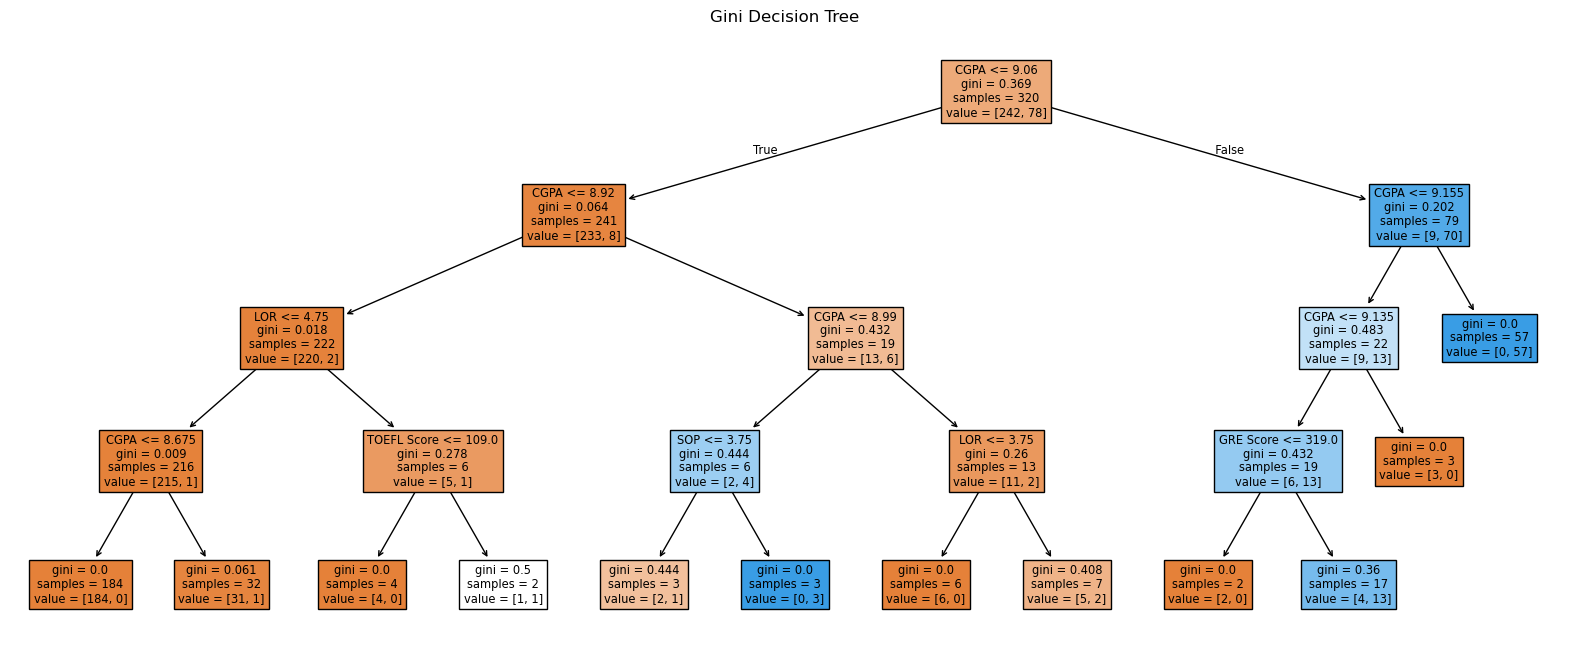

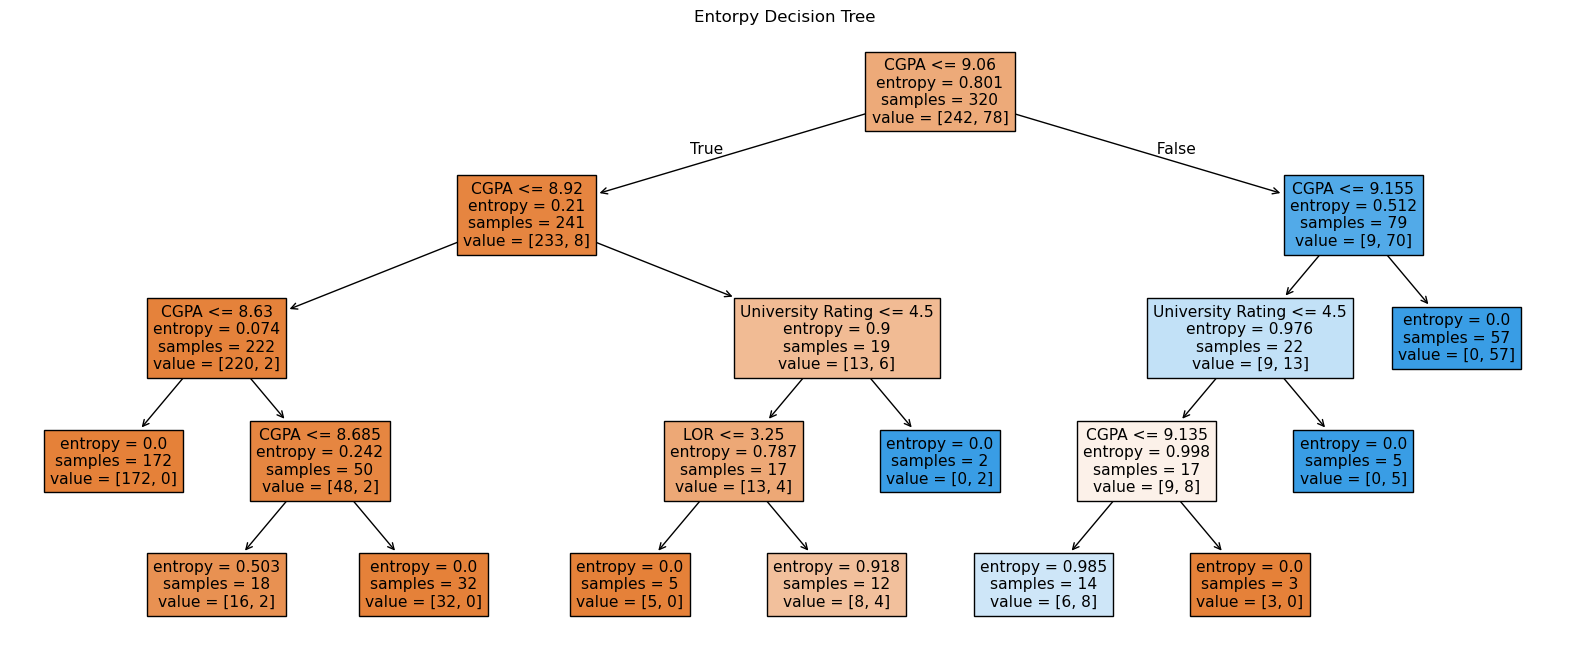

In [8]:
# block 6  vizualization of tree #### most imp ###########
plt.figure(figsize=(20,8))
plot_tree(dt_gini,max_depth=4,filled=True,feature_names=X.columns)
plt.title("Gini Decision Tree")
plt.show()

plt.figure(figsize=(20,8))
plot_tree(dt_ent,max_depth=4,filled=True,feature_names=X.columns)
plt.title("Entorpy Decision Tree")
plt.show()


 Decision Tree Gini
Accuracy: 91.25
Precision: 78.26
Recall: 90.0
F1 Score: 83.72
              precision    recall  f1-score   support

           0       0.96      0.92      0.94        60
           1       0.78      0.90      0.84        20

    accuracy                           0.91        80
   macro avg       0.87      0.91      0.89        80
weighted avg       0.92      0.91      0.91        80



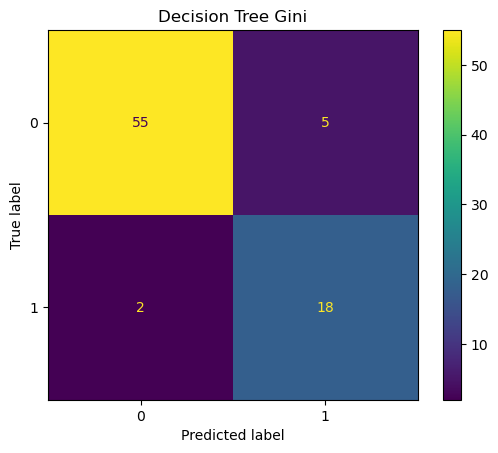


 Decision Tree Entropy
Accuracy: 90.0
Precision: 77.27
Recall: 85.0
F1 Score: 80.95
              precision    recall  f1-score   support

           0       0.95      0.92      0.93        60
           1       0.77      0.85      0.81        20

    accuracy                           0.90        80
   macro avg       0.86      0.88      0.87        80
weighted avg       0.90      0.90      0.90        80



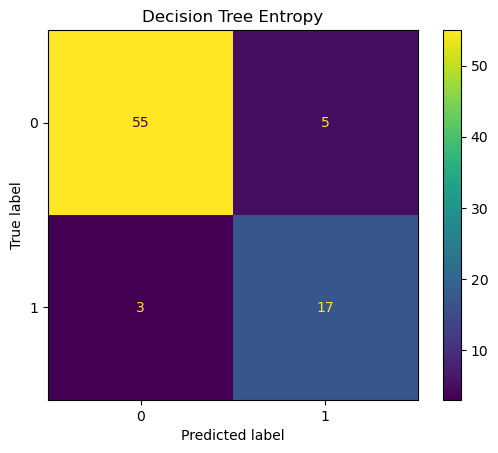


 Naive Bayes
Accuracy: 92.5
Precision: 79.17
Recall: 95.0
F1 Score: 86.36
              precision    recall  f1-score   support

           0       0.98      0.92      0.95        60
           1       0.79      0.95      0.86        20

    accuracy                           0.93        80
   macro avg       0.89      0.93      0.91        80
weighted avg       0.93      0.93      0.93        80



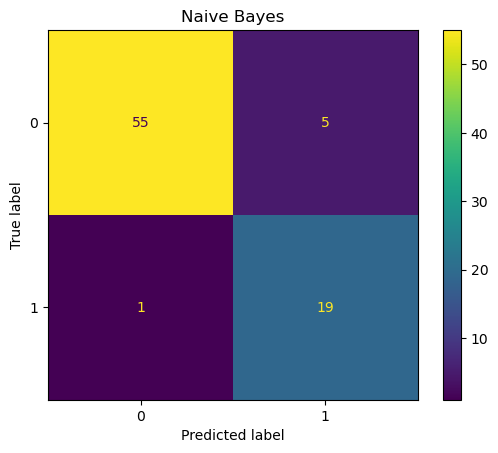

In [40]:
# Function to evaluate model performance
def evaluate(name, y_test, y_pred):
    acc = accuracy_score(y_test, y_pred)
    pre = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print("\n", name)
    print("Accuracy:", round(acc * 100, 2))
    print("Precision:", round(pre * 100, 2))
    print("Recall:", round(rec * 100, 2))
    print("F1 Score:", round(f1 * 100, 2))

    
    print(classification_report(y_test, y_pred))

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
    plt.title(name)
    plt.show()

    return {
        "Model": name,
        "Accuracy": acc * 100,
        "Precision": pre * 100,
        "Recall": rec * 100,
        "F1 Score": f1 * 100
    }

# Store results in a list
results = [
    evaluate("Decision Tree Gini", y_test, y_pred_gini),
    evaluate("Decision Tree Entropy", y_test, y_pred_ent),
    evaluate("Naive Bayes", y_test, y_pred_nb)
]

In [41]:
# Create comparison table
result_df = pd.DataFrame(results).set_index("Model")

display(result_df.round(2))



,Accuracy,Precision,Recall,F1 Score
Model,,,,
Decision Tree Gini,91.25,78.26,90.0,83.72
Decision Tree Entropy,90.00,77.27,85.0,80.95
Naive Bayes,92.50,79.17,95.0,86.36


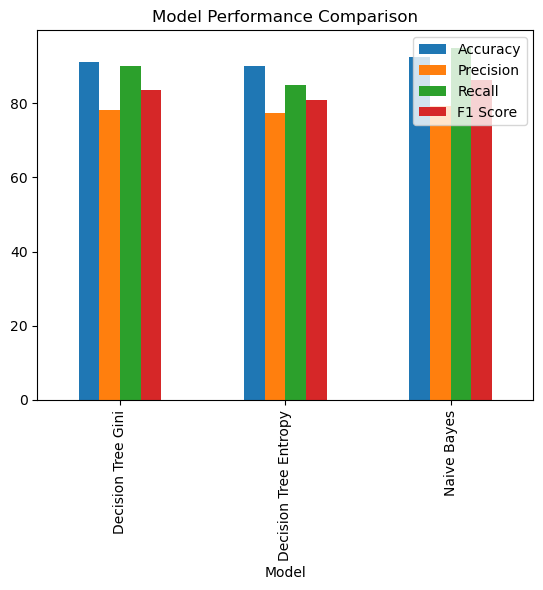

Best Model: Naive Bayes


In [42]:
# Plot comparison graph
result_df.plot(kind="bar")
plt.title("Model Performance Comparison")
plt.show()

# Find best model
print("Best Model:", result_df["F1 Score"].idxmax())